# Analyse des ventes Online Retail : jointure et temps

## Questions métier
1. Quel mois génèrent le plus de CA ?
2. Quel jour et quel heure concentre le plus de commande ?
3. Quels continents pèsent le plus dans le CA ?

In [1]:
import pandas as pd

df = pd.read_csv("../data/processed/online_retail_propre.csv",
                 parse_dates=["InvoiceDate"])

clients = (df.groupby("CustomerID")
             .agg(premier_achat=("InvoiceDate", "min"),
                  nb_commandes=("InvoiceNo", "nunique"),
                  ca_total=("CA", "sum"))
             .reset_index())

n_avant = len(df)
df_m = df.merge(clients, on="CustomerID", how="left",
                validate="m:1", indicator=True)

print(n_avant, "→", len(df_m))
print(df_m["_merge"].value_counts())

C:\Users\lilal\AppData\Local\Temp\ipykernel_42156\3534649900.py:3: DtypeWarning: Columns (0: InvoiceNo) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/processed/online_retail_propre.csv",


524876 → 524876
_merge
both          524876
left_only          0
right_only         0
Name: count, dtype: int64


## Jointure : pays → continent

Pourquoi cette jointure ? Le jeu n’a qu’un seul fichier. Je construis une table de référence continents (38 pays) pour analyser le CA par zone géographique, ce que la colonne Country seule ne permet pas.

Paramètres :
- Clé : Country
- Type : left join, relation m:1 (plusieurs lignes de ventes pour un seul continent par pays)
- validate=« m:1 » : bloque la jointure si un pays apparaît deux fois dans la table de référence
- indicator=True : repère les pays sans correspondance

Contrôle du nombre de lignes :
- Avant : 524 876 lignes
- Après : 524 876 lignes (identique, aucun doublon créé)
- Lignes sans correspondance (`left_only`) : 0

Remarque : les espaces insécables dans Country ont été supprimés avant la jointure (sinon « Finland » n’était pas reconnu).

In [2]:
cont = {
    "Europe": ["United Kingdom", "France", "Germany", "EIRE", "Spain",
               "Netherlands", "Belgium", "Switzerland", "Portugal", "Italy",
               "Norway", "Finland", "Sweden", "Austria", "Denmark", "Poland",
               "Iceland", "Greece", "Malta", "Lithuania", "Czech Republic",
               "Cyprus", "Channel Islands", "European Community"],
    "Amérique du Nord": ["USA", "Canada"],
    "Amérique du Sud": ["Brazil"],
    "Océanie": ["Australia"],
    "Asie": ["Japan", "Hong Kong", "Singapore", "Israel", "Lebanon",
             "Bahrain", "United Arab Emirates", "Saudi Arabia"],
    "Afrique": ["RSA"],
    "Inconnu": ["Unspecified"],
}

continents = pd.DataFrame(
    [(pays, c) for c, pays in cont.items() for pays in pays],
    columns=["Country", "Continent"],
)

n_avant = len(df)
df_m = df.merge(continents, on="Country", how="left",
                validate="m:1", indicator=True)

print(n_avant, "→", len(df_m))
print(df_m["_merge"].value_counts())

524876 → 524876
_merge
both          524876
left_only          0
right_only         0
Name: count, dtype: int64


## Préparation de l’analyse temporelle

Création du dossier figures/ pour enregistrer les graphiques, de l’ordre des jours de la semaine, et de deux colonnes dérivées de InvoiceDate : jour et heure.

In [3]:
import os
import matplotlib.pyplot as plt

os.makedirs("../figures", exist_ok=True)
ordre = ["Monday", "Tuesday", "Wednesday", "Thursday",
         "Friday", "Saturday", "Sunday"]
df_m["jour"] = df_m["InvoiceDate"].dt.day_name()
df_m["heure"] = df_m["InvoiceDate"].dt.hour

## Évolution du CA mensuel (£)

**Question :** comment le CA évolue-t-il au fil des mois, et quel mois est le plus fort ?

**Méthode :** resample(« MS ») somme le CA par mois. Décembre 2011 est exclu : les données s’arrêtent début décembre, le mois est incomplet et fausserait la courbe. Un graphique en courbe convient pour suivre une évolution dans le temps.

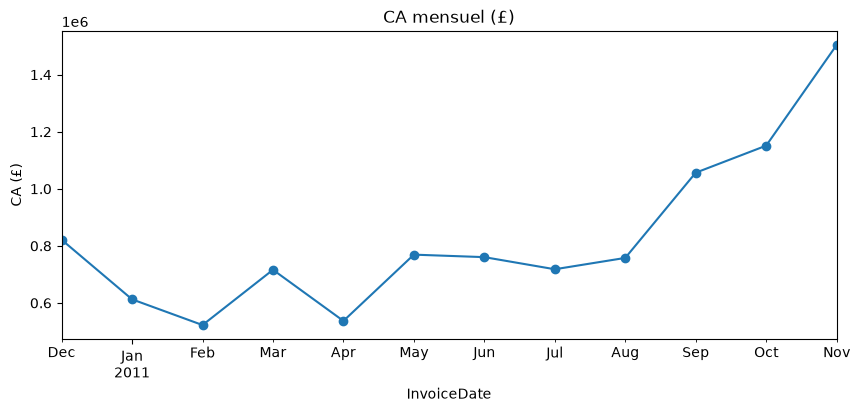

In [4]:
mensuel = df_m.set_index("InvoiceDate").resample("MS")["CA"].sum()
mensuel = mensuel[mensuel.index < "2011-12-01"]

mensuel.plot(marker="o", figsize=(10, 4), title="CA mensuel (£)")
plt.ylabel("CA (£)")
plt.savefig("../figures/ca_mensuel.png", dpi=150, bbox_inches="tight")
plt.show()

**Lecture :** le CA culmine en Novembre > 1.400 000 £, contre une moyenne mensuelle de 800 000 £.

**Conclusion :** le mois de novembre est le mois avec le plus de chiffre d'affaire 

**Limite :** décembre 2011 exclu 

## Commandes par jour de la semaine

**Question :** quels jours les clients commandent-ils le plus ?

**Méthode :** on compte les commandes distinctes (`InvoiceNo` unique) par jour, et non le CA, pour mesurer l’activité plutôt que le montant. Un diagramme en barres convient pour comparer des catégories (les 7 jours).

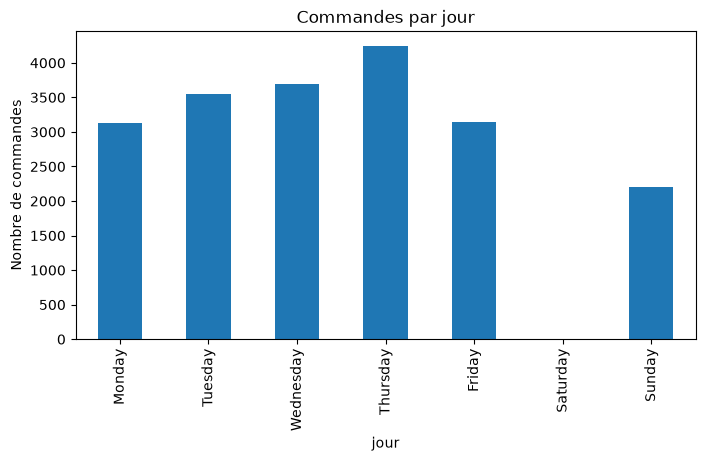

In [5]:
(df_m.groupby("jour")["InvoiceNo"].nunique()
     .reindex(ordre)
     .plot(kind="bar", figsize=(8, 4), title="Commandes par jour"))
plt.ylabel("Nombre de commandes")
plt.savefig("../figures/commandes_jour.png", dpi=150, bbox_inches="tight")
plt.show()

**Lecture :** le jeudi est le jour le plus actif, avec environ 4000 commandes. L’activité monte du lundi au jeudi, puis baisse le vendredi et le dimanche. Il n’y a aucune commande le samedi.

**Conclusion :** la clientèle commande surtout en milieu et fin de semaine, ce qui est cohérent avec une clientèle de revendeurs et de professionnels. L’absence de commandes le samedi indique probablement un jour de fermeture ou de non-saisie.

**Limite :** il s’agit d’un nombre de commandes, pas de montants : un jour avec moins de commandes peut avoir des paniers plus gros. La cause du samedi vide est une hypothèse, à confirmer auprès de la source.

## Commandes par heure de la journée

**Question :** à quelle heure les clients passent-ils commande ?
**Méthode :** on compte les commandes distinctes (`InvoiceNo` unique) par heure de `InvoiceDate`. Un diagramme en barres convient pour comparer des tranches horaires.

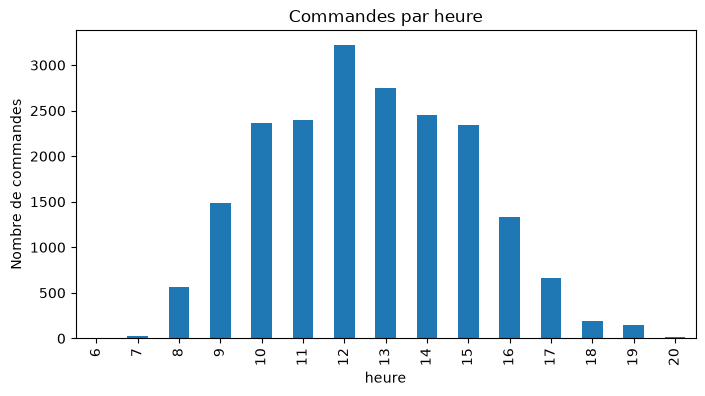

In [6]:
(df_m.groupby("heure")["InvoiceNo"].nunique()
     .plot(kind="bar", figsize=(8, 4), title="Commandes par heure"))
plt.ylabel("Nombre de commandes")
plt.savefig("../figures/commandes_heure.png", dpi=150, bbox_inches="tight")
plt.show()

**Lecture :** l’activité démarre vers 7h, atteint son pic à 12h avec environ 3000 commandes, puis décroît jusqu’à 20h. Aucune commande n’est enregistrée la nuit.

**Conclusion :** les commandes se concentrent sur les heures de bureau, avec un pic autour de midi. Cela correspond à une activité professionnelle (B2B) plutôt qu’à des achats de particuliers en soirée.

**Limite :** les heures sont celles du système de facturation (fuseau non précisé), et l’on compte des commandes, pas des montants. Le lien avec une clientèle professionnelle reste une hypothèse.

## CA par continent (£)

**Question :** quelles zones géographiques génèrent le CA, et dans quelle proportion ?

**Méthode :** la tabler `continent` (jointure `m:1`sur `Country`) rattache chaque ligne à un continent. On somme le CA par continent. Un diagramme en barres horizontales convient pour comparer des catégories avec des noms longs, triées par valeur.

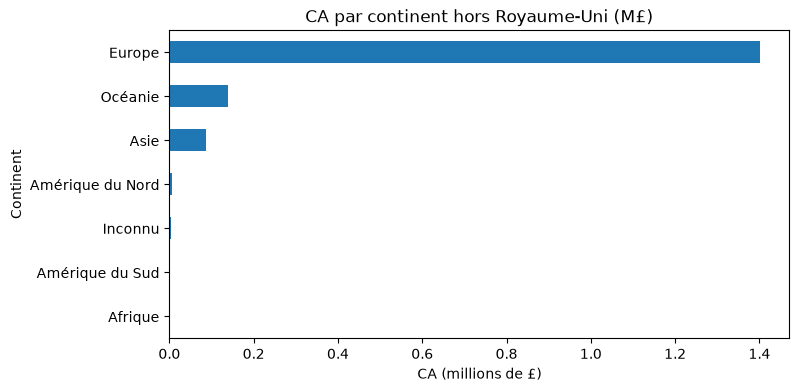

524876 → 44893
Continent
Afrique              0.1
Amérique du Nord     0.4
Amérique du Sud      0.1
Asie                 5.3
Europe              85.4
Inconnu              0.3
Océanie              8.4
Name: CA, dtype: float64


In [7]:
hors_uk = df_m[df_m["Country"] != "United Kingdom"]

(hors_uk.groupby("Continent")["CA"].sum()
        .div(1e6)
        .sort_values()
        .plot(kind="barh", figsize=(8, 4),
              title="CA par continent hors Royaume-Uni (M£)"))
plt.xlabel("CA (millions de £)")
plt.savefig("../figures/ca_continent_hors_uk.png", dpi=150, bbox_inches="tight")
plt.show()

print(len(df_m), "→", len(hors_uk))
print((hors_uk.groupby("Continent")["CA"].sum() / hors_uk["CA"].sum() * 100).round(1))

**Lecture :** l’Europe représente 85,4% du CA hors Royaume-Uni, loin devant l’Océanie, l’Asie et l’Amérique du Nord. 

